# Sesión 5 monitoría

In [1]:
import requests
import pandas as pd
import wikipedia
import matplotlib.pyplot as plt
from sodapy import Socrata
from openai import OpenAI
from IPython.display import display, Image
import openmeteo_requests
import requests_cache
from retry_requests import retry

## Obtener datos de APIs abiertas

### Datos de la bolsa: alphavantage

In [ ]:
url = 'https://www.alphavantage.co/query?function=TIME_SERIES_DAILY&symbol=IBM&apikey=demo'
r = requests.get(url)
data = r.json()

print(data)

{'Meta Data': {'1. Information': 'Daily Prices (open, high, low, close) and Volumes', '2. Symbol': 'AMZN', '3. Last Refreshed': '2026-09-02', '4. Output Size': 'Compact', '5. Time Zone': 'US/Eastern'}, 'Time Series (Daily)': {'2026-09-02': {'1. open': '254.2550', '2. high': '256.2400', '3. low': '253.4000', '4. close': '254.9800', '5. volume': '23454419'}, '2026-09-01': {'1. open': '254.8300', '2. high': '255.8200', '3. low': '251.9300', '4. close': '254.9200', '5. volume': '31700056'}, '2026-08-31': {'1. open': '263.8250', '2. high': '264.3600', '3. low': '257.1200', '4. close': '259.7700', '5. volume': '46089422'}, '2026-08-28': {'1. open': '258.3200', '2. high': '267.5600', '3. low': '257.7800', '4. close': '266.4300', '5. volume': '49547427'}, '2026-08-27': {'1. open': '259.2300', '2. high': '259.6600', '3. low': '255.0200', '4. close': '256.2600', '5. volume': '35927807'}, '2026-08-26': {'1. open': '261.2750', '2. high': '262.0500', '3. low': '258.2400', '4. close': '260.2800', '5

In [ ]:
df = pd.DataFrame(data["Time Series (Daily)"]).T
df.columns = ["open", "high", "low", "close", "volume"]
df.index = pd.to_datetime(df.index)
df = df.astype(float)
display(df.head(10))

,open,high,low,close,volume
2026-09-02,254.255,256.24,253.400,254.98,23454419.0
2026-09-01,254.830,255.82,251.930,254.92,31700056.0
2026-08-31,263.825,264.36,257.120,259.77,46089422.0
2026-08-28,258.320,267.56,257.780,266.43,49547427.0
2026-08-27,259.230,259.66,255.020,256.26,35927807.0
2026-08-26,261.275,262.05,258.240,260.28,21528373.0
2026-08-25,262.510,263.89,259.830,261.06,25550214.0
2026-08-24,259.600,263.32,259.050,262.07,28070483.0
2026-08-21,260.740,261.09,257.035,258.63,35722956.0
2026-08-20,263.160,263.84,259.520,260.11,28374098.0


In [ ]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 100 entries, 2026-09-02 to 2026-04-13
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    100 non-null    float64
 1   high    100 non-null    float64
 2   low     100 non-null    float64
 3   close   100 non-null    float64
 4   volume  100 non-null    float64
dtypes: float64(5)
memory usage: 4.7 KB


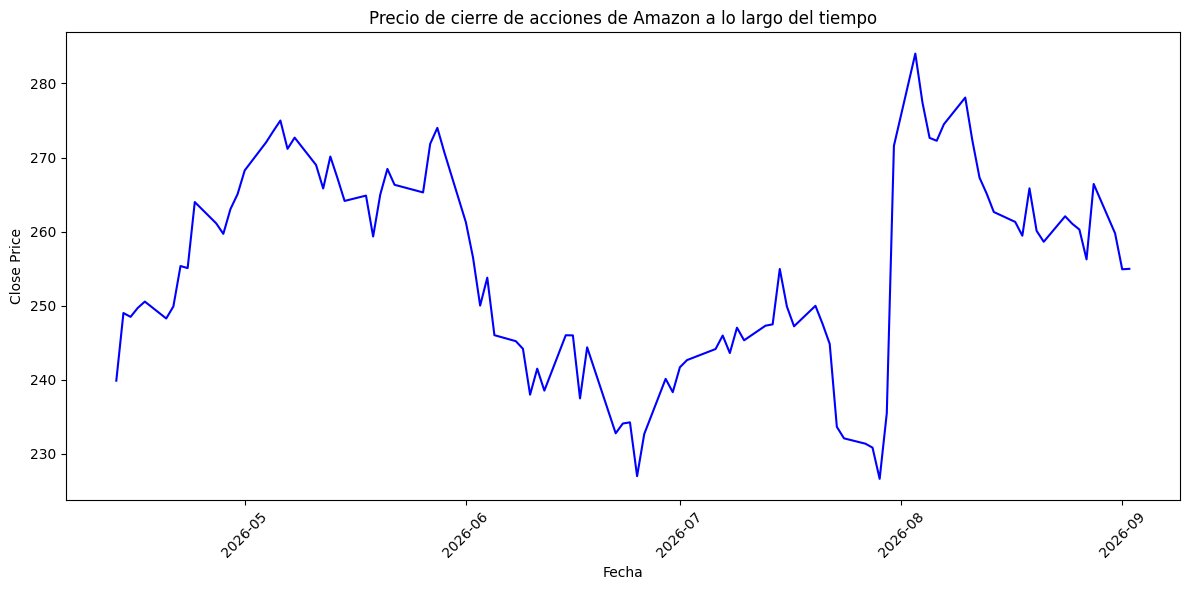

In [ ]:
# Graficar
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['close'], label='Close Price', color='blue')
plt.xlabel('Fecha')
plt.ylabel('Close Price')
plt.title(f'Precio de cierre de acciones de Amazon a lo largo del tiempo')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Datos abiertos Colombia

In [3]:
# Unauthenticated client only works with public data sets. Note 'None'
# in place of application token, and no username or password:
client = Socrata("www.datos.gov.co", None)

# Example authenticated client (needed for non-public datasets):
# client = Socrata(www.datos.gov.co,
#                  MyAppToken,
#                  username="user@example.com",
#                  password="AFakePassword")

# First 8000 results, returned as JSON from API / converted to Python list of
# dictionaries by sodapy.
results = client.get("mcec-87by", limit=8000)

# Convert to pandas DataFrame
results_df = pd.DataFrame.from_records(results)

In [4]:
display(results_df)

,valor,unidad,vigenciadesde,vigenciahasta
0,3140.55,COP,2026-09-03T00:00:00.000,2026-09-03T00:00:00.000
1,3184.0,COP,2026-09-02T00:00:00.000,2026-09-02T00:00:00.000
2,3213.97,COP,2026-09-01T00:00:00.000,2026-09-01T00:00:00.000
3,3202.79,COP,2026-08-29T00:00:00.000,2026-08-31T00:00:00.000
4,3144.28,COP,2026-08-28T00:00:00.000,2026-08-28T00:00:00.000
...,...,...,...,...
7995,775.32,COP,1993-04-24T00:00:00.000,1993-04-26T00:00:00.000
7996,775.05,COP,1993-04-23T00:00:00.000,1993-04-23T00:00:00.000
7997,774.34,COP,1993-04-22T00:00:00.000,1993-04-22T00:00:00.000
7998,773.97,COP,1993-04-21T00:00:00.000,1993-04-21T00:00:00.000


In [5]:
results_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   valor          8000 non-null   str  
 1   unidad         8000 non-null   str  
 2   vigenciadesde  8000 non-null   str  
 3   vigenciahasta  8000 non-null   str  
dtypes: str(4)
memory usage: 250.1 KB


In [6]:
results_df['vigenciadesde']=pd.to_datetime(results_df['vigenciadesde'])
results_df['vigenciahasta']=pd.to_datetime(results_df['vigenciahasta'])
results_df['valor'] = results_df['valor'].astype(float)
results_df

,valor,unidad,vigenciadesde,vigenciahasta
0,3140.55,COP,2026-09-03,2026-09-03
1,3184.00,COP,2026-09-02,2026-09-02
2,3213.97,COP,2026-09-01,2026-09-01
3,3202.79,COP,2026-08-29,2026-08-31
4,3144.28,COP,2026-08-28,2026-08-28
...,...,...,...,...
7995,775.32,COP,1993-04-24,1993-04-26
7996,775.05,COP,1993-04-23,1993-04-23
7997,774.34,COP,1993-04-22,1993-04-22
7998,773.97,COP,1993-04-21,1993-04-21


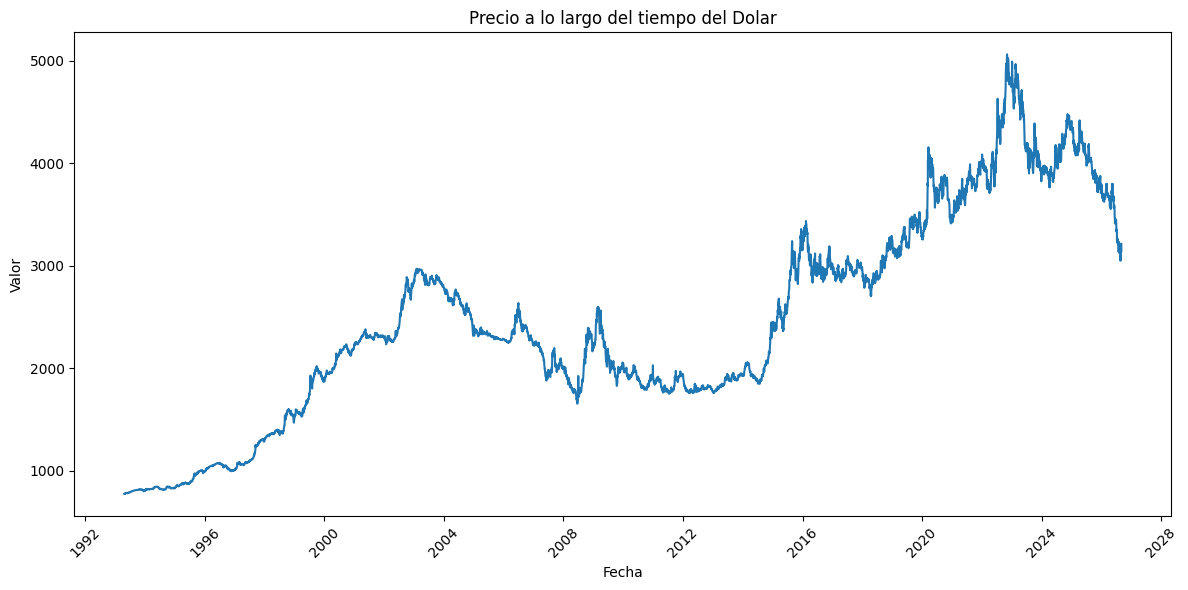

In [7]:
# Graficar
plt.figure(figsize=(12, 6))
plt.plot(results_df['vigenciadesde'], results_df['valor'])
plt.xlabel('Fecha')
plt.ylabel('Valor')
plt.title(f'Precio a lo largo del tiempo del Dolar')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Datos meteorológicos

In [8]:
# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession('.cache', expire_after = 3600)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

# Make sure all required weather variables are listed here
# The order of variables in hourly or daily is important to assign them correctly below
url = "https://api.open-meteo.com/v1/forecast"
params = {
	"latitude": 4.6097,
	"longitude": -74.0818,
	"daily": "precipitation_sum", # <- Dato que estamos obteniendo
	"timezone": "GMT",
}
responses = openmeteo.weather_api(url, params = params)

# Process first location. Add a for-loop for multiple locations or weather models
response = responses[0]
print(f"Coordinates: {response.Latitude()}°N {response.Longitude()}°E")
print(f"Elevation: {response.Elevation()} m asl")
print(f"Timezone: {response.Timezone()}{response.TimezoneAbbreviation()}")
print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

# Process daily data. The order of variables needs to be the same as requested.
daily = response.Daily()
daily_precipitation_sum = daily.Variables(0).ValuesAsNumpy()

daily_data = {
	"date": pd.date_range(
		start = pd.to_datetime(daily.Time(), unit = "s", utc = True),
		end =  pd.to_datetime(daily.TimeEnd(), unit = "s", utc = True),
		freq = pd.Timedelta(seconds = daily.Interval()),
		inclusive = "left"
	)
}

daily_data["precipitation_sum"] = daily_precipitation_sum

daily_dataframe = pd.DataFrame(data = daily_data)
print("\nDaily data\n", daily_dataframe)

Coordinates: 4.674868106842041°N -74.11331176757812°E
Elevation: 2582.0 m asl
Timezone: NoneNone
Timezone difference to GMT+0: 0s

Daily data
                        date  precipitation_sum
0 2026-09-03 00:00:00+00:00                0.4
1 2026-09-04 00:00:00+00:00                0.7
2 2026-09-05 00:00:00+00:00                0.9
3 2026-09-06 00:00:00+00:00                0.0
4 2026-09-07 00:00:00+00:00                0.6
5 2026-09-08 00:00:00+00:00                0.8
6 2026-09-09 00:00:00+00:00                0.7


In [9]:
display(daily_dataframe)

,date,precipitation_sum
0,2026-09-03 00:00:00+00:00,0.4
1,2026-09-04 00:00:00+00:00,0.7
2,2026-09-05 00:00:00+00:00,0.9
3,2026-09-06 00:00:00+00:00,0.0
4,2026-09-07 00:00:00+00:00,0.6
5,2026-09-08 00:00:00+00:00,0.8
6,2026-09-09 00:00:00+00:00,0.7


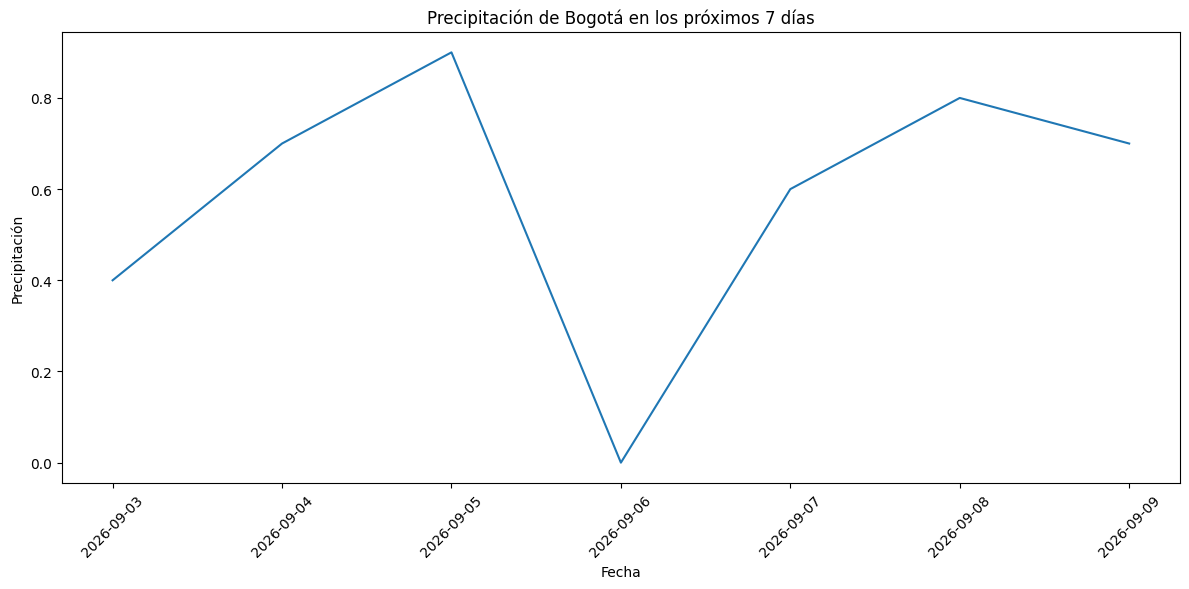

In [10]:
# Graficar
plt.figure(figsize=(12, 6))
plt.plot(daily_dataframe.date, daily_dataframe['precipitation_sum'])
plt.xlabel('Fecha')
plt.ylabel('Precipitación')
plt.title(f'Precipitación de Bogotá en los próximos 7 días')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Indicadores económicos: Banco Mundial

In [11]:
# API del Banco Mundial (World Bank Open Data): abierta y sin API Key
# Indicador NY.GDP.PCAP.CD = PIB per cápita (US$ a precios actuales)
paises = "COL;BRA;CHL;MEX"
indicador = "NY.GDP.PCAP.CD"

url = f"https://api.worldbank.org/v2/country/{paises}/indicator/{indicador}"
params = {
    "format": "json",
    "date": "2000:2023",   # rango de años
    "per_page": 500        # resultados por página
}

data = requests.get(url, params=params).json()

# La respuesta trae dos elementos: [0] metadatos de paginación, [1] los datos
data[0]

{'page': 1,
 'pages': 1,
 'per_page': 500,
 'total': 96,
 'sourceid': '2',
 'lastupdated': '2026-07-13'}

In [12]:
# Los registros vienen anidados, por eso usamos json_normalize
df_bm = pd.json_normalize(data[1])
df_bm = df_bm[["country.value", "date", "value"]]
df_bm.columns = ["pais", "anio", "pib_per_capita"]

df_bm["anio"] = df_bm["anio"].astype(int)
df_bm = df_bm.dropna().sort_values(["pais", "anio"])
df_bm

,pais,anio,pib_per_capita
23,Brazil,2000,3766.548115
22,Brazil,2001,3176.289357
21,Brazil,2002,2855.940189
20,Brazil,2003,3090.607010
19,Brazil,2004,3663.823188
...,...,...,...
76,Mexico,2019,10369.555359
75,Mexico,2020,8841.270749
74,Mexico,2021,10314.050673
73,Mexico,2022,11405.794047


In [13]:
# Una fila por año y una columna por país
tabla_bm = df_bm.pivot(index="anio", columns="pais", values="pib_per_capita")
tabla_bm.head()

pais,Brazil,Chile,Colombia,Mexico
anio,,,,
2000,3766.548115,5052.992458,2555.007510,7524.027138
2001,3176.289357,4563.595299,2472.990840,7952.764795
2002,2855.940189,4430.847412,2428.929698,7983.033984
2003,3090.607010,4773.401775,2311.942188,7434.074650
2004,3663.823188,6120.591521,2818.571954,7849.667596


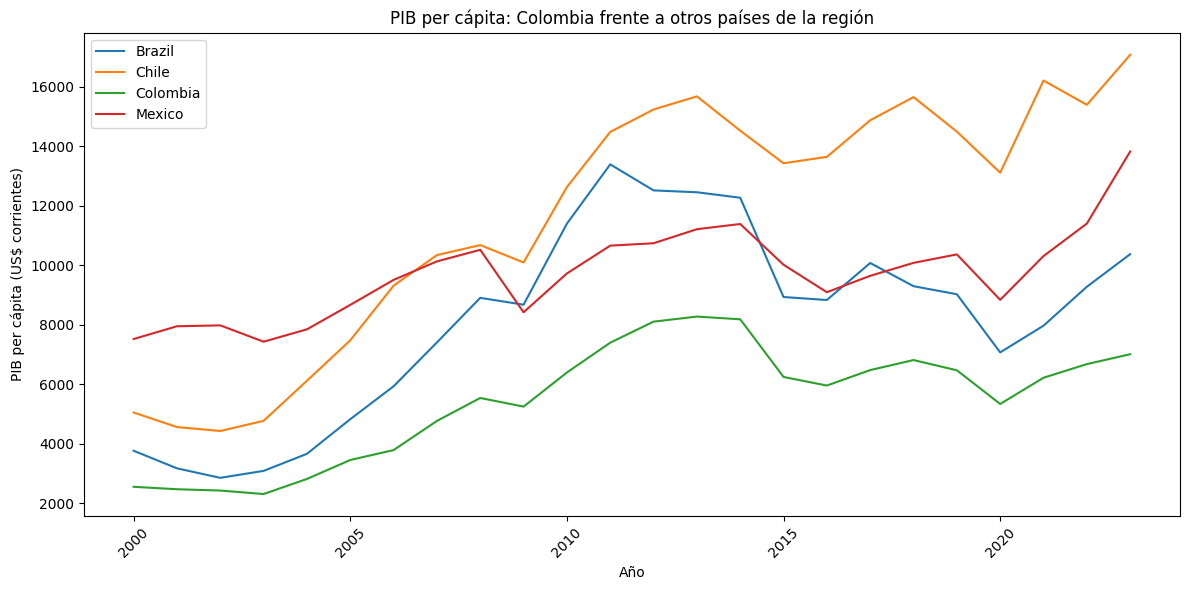

In [14]:
# Graficar
plt.figure(figsize=(12, 6))
for pais in tabla_bm.columns:
    plt.plot(tabla_bm.index, tabla_bm[pais], label=pais)

plt.xlabel('Año')
plt.ylabel('PIB per cápita (US$ corrientes)')
plt.title('PIB per cápita: Colombia frente a otros países de la región')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Wikipedia

In [15]:
wikipedia.set_lang("es")

pagina_1= wikipedia.page("Python")

print(pagina_1.title)
print(pagina_1.summary)


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [ ]:
pagina_4= wikipedia.page("Fútbol")

print(pagina_4.title)
print(pagina_4.summary)


Fútbol
El fútbol, futbol​ o balompié​ (del inglés británico football) es un deporte de equipo jugado entre dos conjuntos de once jugadores cada uno, mientras que los árbitros se ocupan de que las reglas se cumplan correctamente. Es considerado, ampliamente, como el deporte más popular del mundo, pues lo practican unas 270 millones de personas.​ También se le conoce como fútbol 11 por el número de jugadores de un equipo o fútbol asociación, nombre derivado de la «Asociación del Fútbol» (The Football Association), primera federación oficial del mundo en este deporte y que utilizó ese nombre para distinguirlo de otros deportes que incluyen la palabra «fútbol» o «futbol».​ En algunos países de habla inglesa, también se lo conoce como soccer, abreviatura de association, puesto que el nombre de football en esos países se asocia mayoritariamente a otros deportes con esa denominación (principalmente en Estados Unidos, donde el nombre football se aplica al fútbol americano, un deporte totalment

In [ ]:
pagina_4.url

'https://es.wikipedia.org/wiki/F%C3%BAtbol'

## Interactuar con ChatGPT desde Python

In [ ]:
chat_gpt_key=''

In [17]:
# Inicializa el cliente
client = OpenAI(api_key=chat_gpt_key)

In [18]:
prompt = "¿En qué equipo juega Cristiano Ronaldo?"

# Llamada al modelo
response = client.chat.completions.create(
    model="gpt-5-mini",
    messages=[{"role": "user", "content": prompt}],
    temperature=1
)

# Extraer contenido
mensaje = response.choices[0].message.content
print(mensaje)

Hasta mi última actualización (junio de 2024), Cristiano Ronaldo juega en el Al Nassr FC de Arabia Saudí. También sigue siendo internacional con la selección de Portugal.

Si quieres la confirmación en tiempo real, puedo indicarte dónde comprobarlo (sitio oficial del club, cuentas oficiales del jugador o medios deportivos) o buscar la información actual si me lo pides. ¿Quieres que lo compruebe ahora?


In [19]:
import base64

prompt = """
Dibuja un perro salchicha jugando con un gato persa
"""

result = client.images.generate(model="gpt-image-2", prompt=prompt)

image_base64 = result.data[0].b64_json
image_bytes = base64.b64decode(image_base64)

# Save the image to a file
with open("perro.png", "wb") as f:
    f.write(image_bytes)

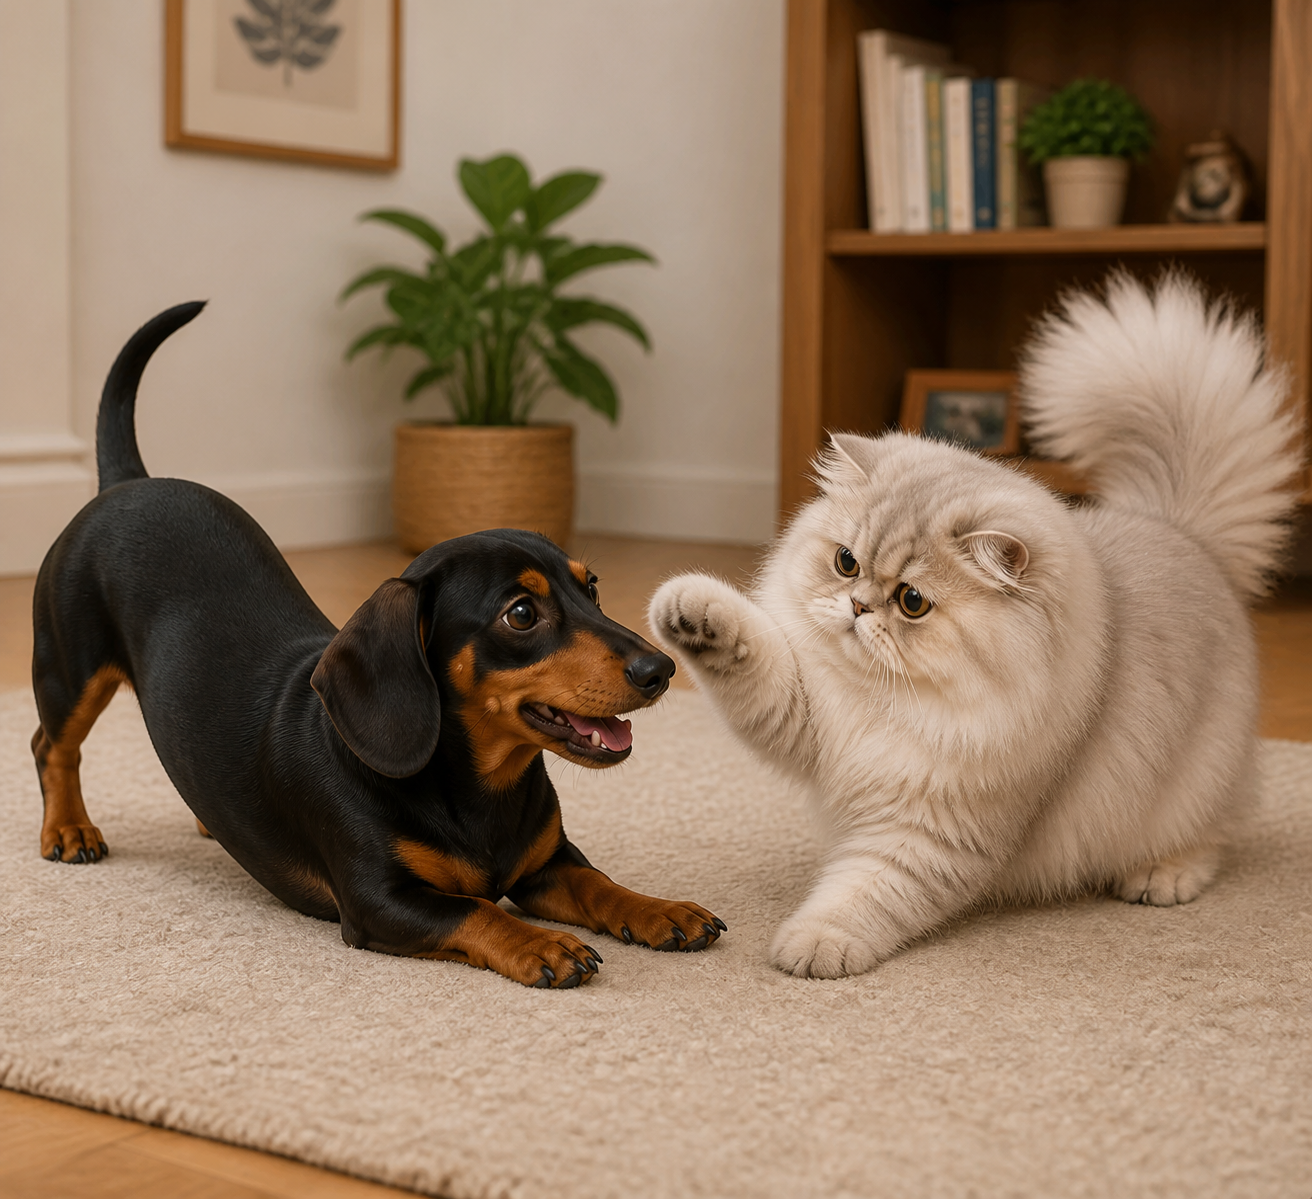

In [20]:
display(Image("perro.png"))

### Aplicación

In [21]:
info_cliente_banca = pd.read_excel('infoclientebanca.xlsx')
info_cliente_banca

,CLIENTE,grupo_de_cliente,Numero_de_transacciones,promedio_por_transaccion,transaccion_minima,transaccion_maxima,desviacion_estandar_por_transaccion,porcentaje_visa_nacional,porcentaje_visa_internacional,porcentaje_mastercard_nacional,...,porcentaje_tarde,porcentaje_noche,porcDOMINGO,porcLUNES,porcMARTES,porcMIERCOLES,porcJUEVES,porcVIERNES,porcSABADO,Sitio_consumo_masfrecuente
0,1,A,1,459930.30,459930.30,459930.3,0.00,0.000000,1.000000,0.0,...,0.00,1.0,0.000000,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,CLINICAS - HOSPITALES
1,2,A,3,582666.70,350000.00,699000.0,201495.23,1.000000,0.000000,0.0,...,1.00,0.0,0.000000,0.666667,0.0,0.000000,0.333333,0.000000,0.000000,MERCADEO DIRECTO - COMERCIANTES DE VENTAS TELE...
2,3,A,3,616547.00,616547.00,616547.0,0.00,1.000000,0.000000,0.0,...,0.00,0.0,0.000000,0.000000,0.0,1.000000,0.000000,0.000000,0.000000,"DROGUERIAS, FARMACIAS, TIENDAS NATURISTAS"
3,4,A,10,144467.10,20000.00,328444.0,116685.81,0.000000,0.000000,1.0,...,0.60,0.0,0.000000,0.600000,0.2,0.000000,0.100000,0.000000,0.100000,ALMACEN POR DEPARTAMENTO CON SUPERMERCADO
4,5,A,1,321764.00,321764.00,321764.0,0.00,1.000000,0.000000,0.0,...,1.00,0.0,1.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,ALMACEN POR DEPARTAMENTO CON SUPERMERCADO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47866,47867,A,1,32600.00,32600.00,32600.0,0.00,1.000000,0.000000,0.0,...,0.00,0.0,0.000000,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,VENTA DE COMIDA RAPIDA
47867,47868,A,22,243821.10,19195.06,404257.2,135337.77,0.090909,0.909091,0.0,...,0.25,0.6,0.090909,0.000000,0.0,0.090909,0.409091,0.272727,0.136364,COMPRAS EN INTERNET
47868,47869,A,5,172848.06,80000.00,400000.0,129609.18,0.200000,0.600000,0.2,...,0.40,0.4,0.200000,0.000000,0.2,0.000000,0.200000,0.200000,0.200000,ALMACEN POR DEPARTAMENTO CON SUPERMERCADO
47869,47870,A,1,90000.00,90000.00,90000.0,0.00,1.000000,0.000000,0.0,...,1.00,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,1.000000,ALMACENES DE VESTUARIO Y ACCESORIOS PARA TODA ...


In [22]:
set_consumo_frecuent= set(info_cliente_banca['Sitio_consumo_masfrecuente'])
len(set_consumo_frecuent)

109

In [24]:
prompt = f"""
Tengo esta lista de categorías de comercios y servicios:

{set_consumo_frecuent}

Quiero agruparlas en un diccionario de Python, donde:

- Las llaves sean categorías generales, por ejemplo (PERO SIN LIMITARSE A ESTAS): 
  Comercio, Salud, Educación, Viajes, Servicios Financieros, Ocio, Alimentación, etc.
- Los valores sean listas con las subcategorías correspondientes de la lista anterior.

Si corresponde, una subcategoría puede aparecer en más de una categoría general.

Necesito que este diccionario sea consistente y listo para generar un one-hot encoding,
ya que quiero agregar esta información a mi base de datos de transacciones de tarjetas de crédito 
para luego hacer clustering de los clientes según sus hábitos de consumo.

"""

response = client.chat.completions.create(
    model="gpt-4o",  
    messages=[{"role": "user", "content": prompt}],
    temperature=0
)

mensaje = response.choices[0].message.content
print(mensaje)

Para crear un diccionario que agrupe las subcategorías en categorías generales, podemos seguir un enfoque lógico basado en las características de cada subcategoría. Aquí tienes un ejemplo de cómo podrías estructurar este diccionario en Python:

```python
categorias_generales = {
    'Comercio': [
        'ALMACENES DE ARTICULOS DE CUERO Y MALETAS',
        'ALMACENES DE MASCOTAS - ALIMENTOS Y ACCESORIOS PARA MASCOTAS',
        'PAPELERIAS ( Almacenes de Artículos para Oficina y colegios)',
        'ALMACENES DE MUSICA - INSTRUMENTOS MUSICALES, PIANOS, PARTITURAS',
        'ALMACENES DE ARTICULOS PARA EL HOGAR',
        'ALMACENES DE CAMARAS Y EQUIPOS FOTOGRAFICOS',
        'ALMACEN DE BICICLETAS VENTA Y SERVICIOS',
        'ALMACENES DE TELAS',
        'ALMACENES DE VESTUARIO Y ACCESORIOS PARA TODA LAFAMILIA',
        'ALMACENES DE MISCELANEAS, CACHARRERIA Y ARTICULOS PARA REGALO / TODO TIPO DE ALMACENES',
        'ALMACENES DE VENTA DE EQUIPOS ELECTRONICOS',
        'ALMACENES DE ELEC

In [25]:
categorias_generales = {
    'Comercio': [
        'ALMACENES DE VESTUARIO Y ACCESORIOS PARA TODA LAFAMILIA',
        'ALMACENES DE ARTICULOS DE CUERO Y MALETAS',
        'ALMACENES DE ARTICULOS PARA EL HOGAR',
        'ALMACENES POR DEPARTAMENTO SIN SUPERMERCADO',
        'ALMACENES DE CALZADO',
        'ALMACENES DE DISCOS',
        'SUPERMERCADOS / TIENDAS EXPRESS',
        'ALMACENES DE ARTICULOS TIPICOS, ANTIGUEDADES ( Ventas, Reparación y Restauración) / PINTURAS / MUSEOS / ARTE',
        'ALMACENES DE VIDRIOS Y ESPEJOS',
        'OUTLETS',
        'ALMACENES DE REPARACIONES ELECTRONICAS',
        'ALMACENES DE CAMARAS Y EQUIPOS FOTOGRAFICOS',
        'ALMACENES DE VENTA DE EQUIPOS ELECTRONICOS',
        'ALMACENES DE JUEGOS, JUGUETES Y HOBBIES',
        'ALMACENES DE MASCOTAS - ALIMENTOS Y ACCESORIOS PARA MASCOTAS',
        'ALMACENES DE TELAS',
        'ALMACENES DE RELOJES, JOYAS Y PLATERIAS',
        'ALMACENES DE MISCELANEAS, CACHARRERIA Y ARTICULOS PARA REGALO / TODO TIPO DE ALMACENES',
        'ALMACENES DE COMPUTADORES Y SOFTWARE',
        'ALMACENES DE ARTICULOS DEPORTIVOS',
        'ALMACENES DE ELECTRODOMESTICOS Y GASODOMESTICOS',
    ],
    'Salud': [
        'LABORATORIOS CLINICOS',
        'CONSULTORIOS Y SERVICIOS MEDICOS',
        'CLINICAS - HOSPITALES',
        'CLINICAS VETERINARIAS Y SERVICIOS VETERINARIOS',
        'MEDICINA PREPAGADA',
        'SERVICIOS DE AMBULANCIA',
        'VENTA DE ARTICULOS MEDICOS, ODONTOLOGICOS, ORTOPEDICOS',
    ],
    'Educación': [
        'COLEGIOS, UNIVERSIDADES , INSTITUTOS DE EDUCACION TECNOLOGICA Y PREESCOLAR',
        'ESCUELAS DE ENSEÑANZA INFORMAL',
    ],
    'Viajes': [
        'HOTELES - CENTROS VACACIONALES',
        'AEROLINEAS',
        'COMPAÑIAS DE AVIACION',
        'AGENCIAS DE VIAJE y OPERADORES DE TURISMO',
        'COMPAÑIAS DE ALQUILER DE VEHICULOS',
        'TRANSPORTE DE PASAJEROS, TERRESTRE, FLUVIAL y MARITIMO',
    ],
    'Servicios Financieros': [
        'ASEGURADORAS',
        'ENTIDADES FINANCIERAS',
        'PAGO DE IMPUESTOS / PAGOS DE TDC',
    ],
    'Ocio': [
        'CLUBES SOCIALES Y DEPORTIVOS',
        'SERVICIOS DE RECREACION',
        'CASINOS Y JUEGOS DE AZAR , LOTERIAS, RIFAS',
        'SALAS DE CINE',
        'CONGRESOS Y SEMINARIOS',
        'EVENTOS, FIESTAS Y BANQUETES',
        'GRILES -WISKERIAS- NIGT CLUB -STRIP TEASE',
    ],
    'Alimentación': [
        'SALSAMENTARIAS y VENTAS DE CARNES',
        'RESTAURANTES, PIZZERIAS, FUENTES DE SODA',
        'VENTA DE COMIDA RAPIDA',
        'PANADERIAS, REPOSTERIAS, SALONES DE TE Y CAFETERIAS',
        'DULCERIAS',
    ],
    'Servicios': [
        'LAVANDERIAS - LAVASECOS',
        'SERVICIOS FUNERARIOS Y PARQUES CEMENTARIOS',
        'SERVICIOS DE MENSAJERIA, CORREO y ENCOMIENDAS',
        'SERVITECAS Y LLANTAS',
        'SERVICIOS Y ASESORIAS PROFESIONALES',
        'SERVICIOS PUBLICOS',
        'SERVICIOS DE PUBLICIDAD, MEDIOS Y ARTES GRAFICAS',
        'SERVICIIOS DE REPRODUCCCION Y FOTOCOPIAS',
        'ADMINISTRACION DE AREAS COMUNES, SERVICIOS DE LIMPIEZA, MANTENIMIENTO Y CELADURIA',
    ],
    'Tecnología': [
        'COMPUTADORES - EQUIPOS - ACCESORIOS - SOTFWARE',
        'VENTA DE EQUIPOS Y SERVICIOS DE TELECOMUNICACIONES',
        'SUSCRIPCION T.V POR CABLE Y OTROS SERVICIOS DE RADIO Y TELEVISION PAGOS',
    ],
    'Construcción': [
        'CONTRATISTAS GENERALES - RESIDENCIALES Y COMERCIALES',
        'DEPOSITO DE MATERIALES DE CONSTRUCCION',
        'DISTRIBUIDORES DE MATERIALES PARA COMBUSTIBLE, CARBON, ACEITE COMBUSTIBLE PETROLEO LIQUIDO, MADERA',
        'FERRETERIAS',
    ],
    'Automotriz': [
        'VENTA DE VEHICULOS AUTOMOTORES Y MOTOCICLETAS',
        'TALLERES DE MECANICA Y LATONERIA Y PINTURA Y SERVICIIOS DE GRUA',
        'REPUESTOS Y ACCESORIOS AUTOMOTRICES',
        'GARAJES Y PARQUEADEROS',
    ],
    'Moda y Belleza': [
        'PERFUMERIAS y TIENDA DE COSMESTICOS',
        'SALONES DE BELLEZA - PELUQUERIAS',
        'SASTRES, MODISTAS, CLINICAS DE ROPA',
    ],
    'Otros': [
        'MERCADEO DIRECTO - COMERCIANTES DE VENTAS TELEFONICAS / DIRECTV',
        'MERCADEO DIRECTO - COMERCIANTES DE VENTAS TELEFONICAS / AMWAY',
        'MERCADEO DIRECTO - SERVICIOS DE SEGUROS',
        'COMPRAS EN INTERNET',
        'ORGANIZACIONES DE SERVICIO SOCIAL y DE CARIDAD',
        'SIN NOMBRE',
        'INSUMOS INDUSTRIALES',
        'ASOCIACIONES PROFESIONALES Y GREMIOS',
    ]
}

In [26]:
for categoria, subcategorias in categorias_generales.items():
    info_cliente_banca[categoria] = info_cliente_banca["Sitio_consumo_masfrecuente"].apply(
        lambda x: 1 if x in subcategorias else 0
    )

# Revisar el resultado
pd.set_option('display.max_columns', None)
info_cliente_banca.head(10)

,CLIENTE,grupo_de_cliente,Numero_de_transacciones,promedio_por_transaccion,transaccion_minima,transaccion_maxima,desviacion_estandar_por_transaccion,porcentaje_visa_nacional,porcentaje_visa_internacional,porcentaje_mastercard_nacional,porcentaje_mastercard_internacional,Porcentaje_otrafranquicia_nacional,porcentaje_otrafranquicia_internacional,porcentaje_nacional_total,porcentaje_internacional_total,porcentaje_manana,porcentaje_tarde,porcentaje_noche,porcDOMINGO,porcLUNES,porcMARTES,porcMIERCOLES,porcJUEVES,porcVIERNES,porcSABADO,Sitio_consumo_masfrecuente,Comercio,Salud,Educación,Viajes,Servicios Financieros,Ocio,Alimentación,Servicios,Tecnología,Construcción,Automotriz,Moda y Belleza,Otros
0,1,A,1,459930.30,459930.3,459930.3,0.00,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.00,0.00,1.0,0.0,0.000000,1.0,0.00,0.000000,0.0,0.0,CLINICAS - HOSPITALES,0,1,0,0,0,0,0,0,0,0,0,0,0
1,2,A,3,582666.70,350000.0,699000.0,201495.23,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.00,1.00,0.0,0.0,0.666667,0.0,0.00,0.333333,0.0,0.0,MERCADEO DIRECTO - COMERCIANTES DE VENTAS TELE...,0,0,0,0,0,0,0,0,0,0,0,0,0
2,3,A,3,616547.00,616547.0,616547.0,0.00,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.00,0.00,0.0,0.0,0.000000,0.0,1.00,0.000000,0.0,0.0,"DROGUERIAS, FARMACIAS, TIENDAS NATURISTAS",0,0,0,0,0,0,0,0,0,0,0,0,0
3,4,A,10,144467.10,20000.0,328444.0,116685.81,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.40,0.60,0.0,0.0,0.600000,0.2,0.00,0.100000,0.0,0.1,ALMACEN POR DEPARTAMENTO CON SUPERMERCADO,0,0,0,0,0,0,0,0,0,0,0,0,0
4,5,A,1,321764.00,321764.0,321764.0,0.00,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.00,1.00,0.0,1.0,0.000000,0.0,0.00,0.000000,0.0,0.0,ALMACEN POR DEPARTAMENTO CON SUPERMERCADO,0,0,0,0,0,0,0,0,0,0,0,0,0
5,6,A,2,2847849.00,1735698.0,3960000.0,1572819.00,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.50,0.50,0.0,0.0,0.500000,0.0,0.00,0.000000,0.5,0.0,MERCADEO DIRECTO - SERVICIOS DE SEGUROS,0,0,0,0,0,0,0,0,0,0,0,0,1
6,7,A,1,473925.60,473925.6,473925.6,0.00,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.00,0.00,1.0,0.0,0.000000,0.0,1.00,0.000000,0.0,0.0,SIN NOMBRE,0,0,0,0,0,0,0,0,0,0,0,0,1
7,8,A,4,399208.25,200000.0,493833.0,134891.45,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.75,0.25,0.0,0.0,0.500000,0.0,0.25,0.250000,0.0,0.0,SIN NOMBRE,0,0,0,0,0,0,0,0,0,0,0,0,1
8,9,A,1,3347852.00,3347852.0,3347852.0,0.00,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.00,0.00,0.0,0.0,1.000000,0.0,0.00,0.000000,0.0,0.0,SIN NOMBRE,0,0,0,0,0,0,0,0,0,0,0,0,1
9,10,A,5,215901.40,114707.0,331000.0,104669.53,0.4,0.0,0.6,0.0,0.0,0.0,1.0,0.0,0.20,0.80,0.0,0.0,0.000000,0.2,0.20,0.200000,0.2,0.2,SUPERMERCADOS / TIENDAS EXPRESS,1,0,0,0,0,0,0,0,0,0,0,0,0
